# ⛳ Pelotas de golf y multiplicadores de Lagrange
**Técnicas de Optimización — UPB**

El fabricante Pro-T modela su ganancia (miles de USD) en función de $x$ (miles de pelotas vendidas al mes) y $y$ (horas de publicidad al mes):

$$z = f(x,y) = 48x + 96y - x^2 - 2xy - 9y^2$$

sujeto a la restricción de presupuesto:

$$g(x,y) = 20x + 4y = 216$$

**Objetivo:** hallar $x$ y $y$ que maximizan la ganancia y la ganancia máxima.

**Contenido**
1. Solución analítica por multiplicadores de Lagrange
2. Verificación simbólica con SymPy
3. Clasificación de puntos críticos (máximos y mínimos)
4. Gráfica 2D: isolíneas, gradientes y restricción
5. Gráfica 3D: superficie y curva restringida
6. Exploración interactiva (Plotly + ipywidgets)
7. App de Streamlit para usuarios no técnicos

In [1]:
# Si falta alguna librería, descomenta:
# %pip install numpy sympy matplotlib plotly ipywidgets streamlit
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go

## 1. Solución analítica

Se construye el lagrangiano
$$\mathcal{L}(x,y,\lambda) = 48x + 96y - x^2 - 2xy - 9y^2 - \lambda\,(20x + 4y - 216)$$

Condiciones de primer orden ($\nabla f = \lambda \nabla g$):

$$
\begin{cases}
\mathcal{L}_x: & 48 - 2x - 2y = 20\lambda \\
\mathcal{L}_y: & 96 - 2x - 18y = 4\lambda \\
\mathcal{L}_\lambda: & 20x + 4y = 216
\end{cases}
$$

**Paso 1.** De la segunda ecuación: $\lambda = \dfrac{96 - 2x - 18y}{4}$. Sustituyendo en la primera:
$$48 - 2x - 2y = 5(96 - 2x - 18y) \;\Rightarrow\; 8x + 88y = 432 \;\Rightarrow\; x + 11y = 54$$

**Paso 2.** De la restricción: $y = 54 - 5x$. Entonces $x + 11(54 - 5x) = 54 \Rightarrow 54x = 540$:
$$\boxed{x = 10,\quad y = 4}$$

**Paso 3.** $\lambda = \dfrac{48 - 20 - 8}{20} = \boxed{1}$ y
$$f(10,4) = 480 + 384 - 100 - 80 - 144 = \boxed{540 \text{ mil USD}}$$

**Interpretación de $\lambda$:** cada mil dólares adicionales de presupuesto aumentan la ganancia máxima en aproximadamente mil dólares.

## 2. Verificación con SymPy

In [2]:
x, y, lam = sp.symbols('x y lambda', real=True)
f = 48*x + 96*y - x**2 - 2*x*y - 9*y**2
g = 20*x + 4*y - 216
L = f - lam*g

ecuaciones = [sp.Eq(sp.diff(L, v), 0) for v in (x, y, lam)]
display(*ecuaciones)

sol = sp.solve(ecuaciones, [x, y, lam], dict=True)[0]
z_max = f.subs(sol)
print(f"x* = {sol[x]},  y* = {sol[y]},  λ = {sol[lam]},  f(x*, y*) = {z_max} mil USD")

Eq(-20*lambda - 2*x - 2*y + 48, 0)

Eq(-4*lambda - 2*x - 18*y + 96, 0)

Eq(-20*x - 4*y + 216, 0)

x* = 10,  y* = 4,  λ = 1,  f(x*, y*) = 540 mil USD


## 3. Clasificación: ¿máximo o mínimo?

**Con restricción.** Al sustituir $y = 54 - 5x$, la ganancia queda como una función de una variable. Si es una parábola cóncava, el punto crítico es un máximo.

**Sin restricción.** Se busca $\nabla f = 0$ y se analiza el Hessiano.

**Hessiano orlado.** Para el problema con restricción, $\det(\bar H) > 0$ en dos variables con una restricción indica máximo.

In [3]:
# (a) Sustitución en la restricción
h = sp.expand(f.subs(y, 54 - 5*x))
print("f sobre la restricción:", h, " -> coef. de x² =", sp.Poly(h, x).LC(), "(< 0, cóncava → máximo)")

# (b) Hessiano orlado
H_orl = sp.Matrix([[0, 20, 4],
                   [20, sp.diff(L, x, x), sp.diff(L, x, y)],
                   [4, sp.diff(L, y, x), sp.diff(L, y, y)]])
display(H_orl)
print("det(Hessiano orlado) =", H_orl.det(), "(> 0 → máximo condicionado)")

# (c) Óptimo libre
libre = sp.solve([sp.diff(f, x), sp.diff(f, y)], [x, y], dict=True)[0]
H = sp.hessian(f, (x, y))
print("\nPunto crítico libre:", libre, " f =", f.subs(libre))
print("Hessiano:", H.tolist(), " det =", H.det(), " f_xx =", H[0, 0], "→ máximo global (f cóncava)")
print("Costo del óptimo libre:", g.subs(libre) + 216, "mil USD > 216 → la restricción sí limita")

# (d) Mínimo sobre el tramo factible (x, y >= 0): extremos del segmento
for p in ({x: 0, y: 54}, {x: sp.Rational(54, 5), y: 0}):
    print("Extremo", p, "→ f =", float(f.subs(p)))
print("f es cóncava: no hay mínimo global; el mínimo sobre el presupuesto está en (0, 54).")

f sobre la restricción: -216*x**2 + 4320*x - 21060  -> coef. de x² = -216 (< 0, cóncava → máximo)


Matrix([
[ 0, 20,   4],
[20, -2,  -2],
[ 4, -2, -18]])

det(Hessiano orlado) = 6912 (> 0 → máximo condicionado)

Punto crítico libre: {x: 21, y: 3}  f = 648
Hessiano: [[-2, -2], [-2, -18]]  det = 32  f_xx = -2 → máximo global (f cóncava)
Costo del óptimo libre: 432 mil USD > 216 → la restricción sí limita
Extremo {x: 0, y: 54} → f = -21060.0
Extremo {x: 54/5, y: 0} → f = 401.76
f es cóncava: no hay mínimo global; el mínimo sobre el presupuesto está en (0, 54).


## 4. Gráfica 2D: isolíneas, gradientes y restricción

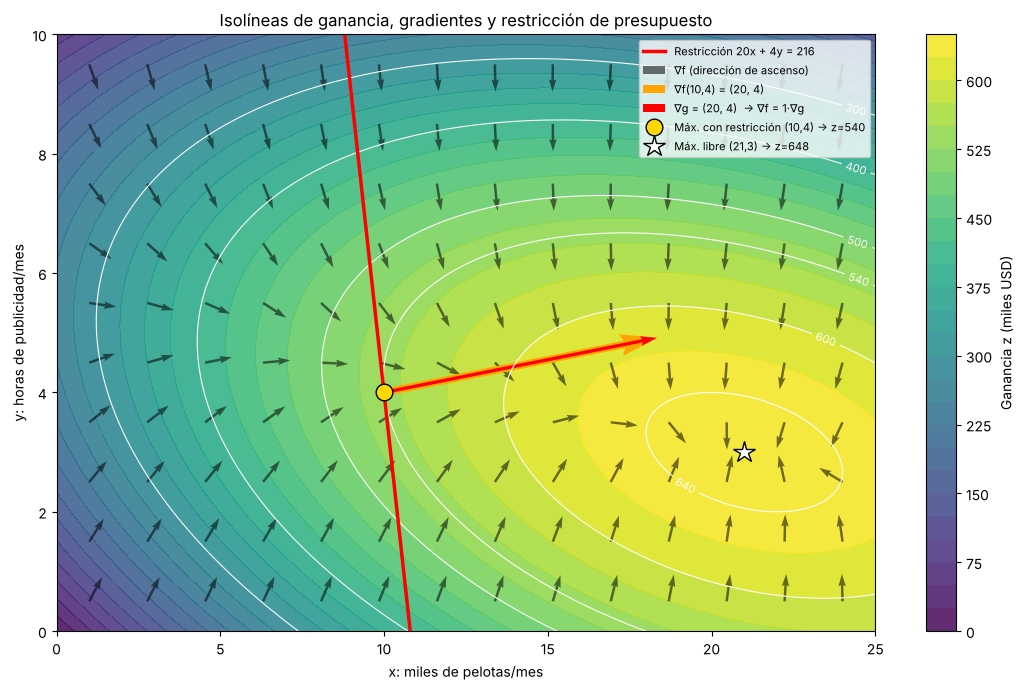

In [4]:
fn = sp.lambdify((x, y), f, 'numpy')
grad = lambda X, Y: (48 - 2*X - 2*Y, 96 - 2*X - 18*Y)
g_y = lambda X: (216 - 20*X) / 4

X_OPT, Y_OPT, Z_OPT = 10, 4, 540
X_LIB, Y_LIB, Z_LIB = 21, 3, 648

xv, yv = np.linspace(0, 25, 300), np.linspace(0, 10, 300)
XX, YY = np.meshgrid(xv, yv)
ZZ = fn(XX, YY)

fig, ax = plt.subplots(figsize=(11, 7))
cf = ax.contourf(XX, YY, ZZ, levels=30, cmap="viridis", alpha=0.85)
cs = ax.contour(XX, YY, ZZ, levels=[300, 400, 500, 540, 600, 640], colors="white", linewidths=0.8)
ax.clabel(cs, fmt="%d", fontsize=8)
fig.colorbar(cf, label="Ganancia z (miles USD)")

xs = np.linspace(0, 10.8, 100)
ax.plot(xs, g_y(xs), "r-", lw=2.5, label="Restricción 20x + 4y = 216")

xq, yq = np.meshgrid(np.linspace(1, 24, 14), np.linspace(0.5, 9.5, 10))
gx, gy = grad(xq, yq)
n = np.hypot(gx, gy); n[n == 0] = 1
ax.quiver(xq, yq, gx/n, gy/n, color="black", alpha=0.55, scale=30, width=0.003, label="∇f (dirección de ascenso)")

ax.quiver(X_OPT, Y_OPT, *grad(X_OPT, Y_OPT), color="orange", scale=60, width=0.009, label="∇f(10,4) = (20, 4)")
ax.quiver(X_OPT, Y_OPT, 20, 4, color="red", scale=60, width=0.004, label="∇g = (20, 4)  → ∇f = 1·∇g")

ax.plot(X_OPT, Y_OPT, "o", ms=12, mfc="gold", mec="k", label=f"Máx. con restricción ({X_OPT},{Y_OPT}) → z={Z_OPT}")
ax.plot(X_LIB, Y_LIB, "*", ms=16, mfc="white", mec="k", label=f"Máx. libre ({X_LIB},{Y_LIB}) → z={Z_LIB}")
ax.set(xlim=(0, 25), ylim=(0, 10), xlabel="x: miles de pelotas/mes", ylabel="y: horas de publicidad/mes",
       title="Isolíneas de ganancia, gradientes y restricción de presupuesto")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Lectura:** en el óptimo la recta de presupuesto es **tangente** a la isolínea $z = 540$. Por eso $\nabla f$ y $\nabla g$ son paralelos. Aquí además coinciden, porque $\lambda = 1$. Las flechas negras convergen hacia la estrella, que es el máximo libre e inalcanzable con este presupuesto.

## 5. Gráfica 3D: superficie y curva restringida

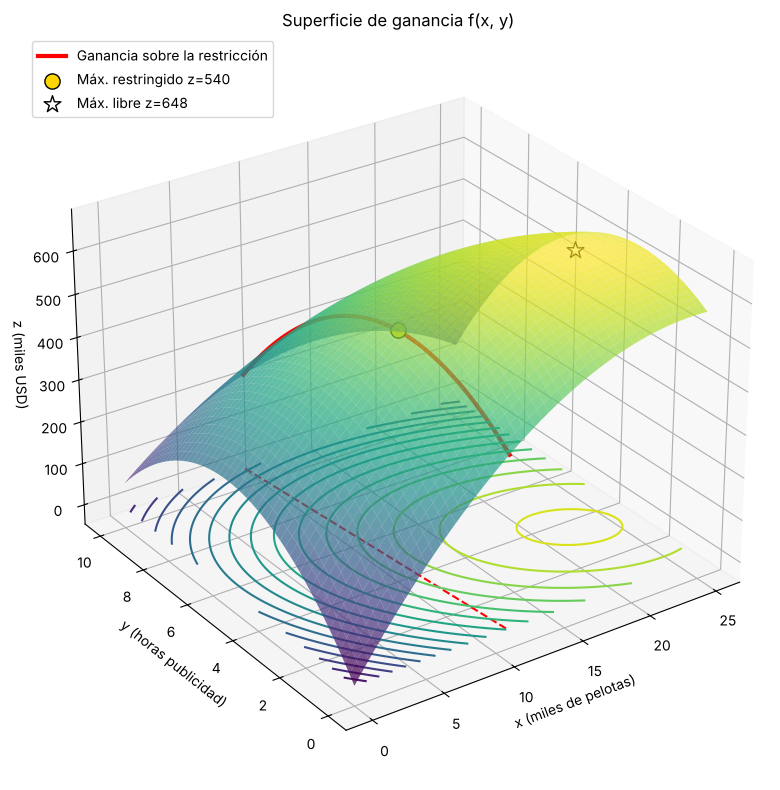

In [5]:
xs3 = np.linspace(8.8, 10.8, 100)   # tramo de la restricción con 0 <= y <= 10
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(XX, YY, ZZ, cmap="viridis", alpha=0.7, linewidth=0)
ax.contour(XX, YY, ZZ, levels=20, zdir="z", offset=ZZ.min(), cmap="viridis")
ax.plot(xs3, g_y(xs3), fn(xs3, g_y(xs3)), "r-", lw=3, label="Ganancia sobre la restricción")
ax.plot(xs3, g_y(xs3), np.full_like(xs3, ZZ.min()), "r--", lw=1.5)
ax.scatter(X_OPT, Y_OPT, Z_OPT, s=120, c="gold", edgecolors="k", depthshade=False, label=f"Máx. restringido z={Z_OPT}")
ax.scatter(X_LIB, Y_LIB, Z_LIB, s=160, c="white", marker="*", edgecolors="k", depthshade=False, label=f"Máx. libre z={Z_LIB}")
ax.set(xlabel="x (miles de pelotas)", ylabel="y (horas publicidad)", zlabel="z (miles USD)",
       title="Superficie de ganancia f(x, y)")
ax.view_init(elev=28, azim=-125); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 6. Exploración interactiva

### 6.1 Superficie 3D con Plotly
Se puede girar y hacer zoom.

In [6]:
fig3 = go.Figure()
fig3.add_surface(x=xv, y=yv, z=ZZ, colorscale="Viridis", opacity=0.85, showscale=False,
                 contours=dict(z=dict(show=True, usecolormap=True, project_z=True)))
fig3.add_scatter3d(x=xs3, y=g_y(xs3), z=fn(xs3, g_y(xs3)), mode="lines",
                   line=dict(color="red", width=8), name="Restricción")
fig3.add_scatter3d(x=[X_OPT], y=[Y_OPT], z=[Z_OPT], mode="markers", name="Máx. restringido (10, 4)",
                   marker=dict(size=7, color="gold", line=dict(color="black", width=2)))
fig3.add_scatter3d(x=[X_LIB], y=[Y_LIB], z=[Z_LIB], mode="markers", name="Máx. libre (21, 3)",
                   marker=dict(size=7, color="white", symbol="diamond", line=dict(color="black", width=2)))
fig3.update_layout(scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z"), height=600,
                   margin=dict(l=0, r=0, t=30, b=0), title="Superficie de ganancia (interactiva)")
fig3.show()

### 6.2 Análisis de sensibilidad con ipywidgets
Mueve los controles para cambiar los costos y el presupuesto. El sistema $\nabla f = \lambda\nabla g$, $ax + by = B$ es **lineal**, así que se resuelve con `np.linalg.solve`. Si el presupuesto alcanza para el máximo libre, $\lambda = 0$ y se recomienda $(21, 3)$.

> Los widgets necesitan un kernel activo. En GitHub o en una vista estática no se mueven.

In [7]:
import ipywidgets as w

def resolver(a, b, B):
    A = np.array([[-2, -2, -a], [-2, -18, -b], [a, b, 0]], float)
    xs_, ys_, l_ = np.linalg.solve(A, [-48, -96, B])
    if a*21 + b*3 <= B:                     # el presupuesto sobra → óptimo libre
        return 21.0, 3.0, 0.0
    if xs_ < 0 or ys_ < 0:                  # recorte a la región factible
        xs_ = np.clip(xs_, 0, B/a); ys_ = (B - a*xs_)/b
    return xs_, ys_, l_

@w.interact(a=w.FloatSlider(20, min=5, max=40, step=0.5, description="Costo/mil pelotas"),
            b=w.FloatSlider(4, min=1, max=20, step=0.5, description="Costo/hora pub."),
            B=w.FloatSlider(216, min=50, max=600, step=1, description="Presupuesto"))
def sensibilidad(a, b, B):
    xo, yo, lo = resolver(a, b, B)
    zo = fn(xo, yo)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.contourf(XX, YY, ZZ, levels=30, cmap="viridis", alpha=0.85)
    ax.contour(XX, YY, ZZ, levels=[zo], colors="white", linewidths=1.5, linestyles="--")
    xl = np.linspace(0, B/a, 200)
    ax.plot(xl, (B - a*xl)/b, "r-", lw=2.5, label=f"{a:g}x + {b:g}y = {B:g}")
    ax.plot(xo, yo, "o", ms=12, mfc="gold", mec="k", label=f"Óptimo ({xo:.2f}, {yo:.2f})")
    ax.plot(21, 3, "*", ms=15, mfc="white", mec="k", label="Máx. libre (21, 3)")
    ax.set(xlim=(0, 25), ylim=(0, 10), xlabel="x (miles de pelotas)", ylabel="y (horas publicidad)",
           title=f"Ganancia máx. = {zo:,.1f} mil USD   |   λ = {lo:.3f}")
    ax.legend(loc="upper right", fontsize=8); plt.show()

interactive(children=(FloatSlider(value=20.0, description='Costo/mil pelotas', max=40.0, min=5.0, step=0.5), F…

## 7. App de Streamlit para usuarios no técnicos

La siguiente celda guarda la app en `app.py`. Para usarla:

1. Ejecuta la celda.
2. Abre una terminal en la misma carpeta del notebook.
3. Corre `streamlit run app.py`. Se abre en el navegador en `http://localhost:8501`.

La app muestra la respuesta en lenguaje sencillo, deja cambiar costos y presupuesto, e incluye un explorador para repartir el presupuesto a mano, el mapa 2D, la montaña 3D y la explicación paso a paso.

In [8]:
%%writefile app.py
"""
App interactiva: ¿Cuántas pelotas producir y cuánta publicidad pagar?
Problema Pro-T resuelto con multiplicadores de Lagrange.

Ejecutar:  streamlit run app.py
"""
import numpy as np
import plotly.graph_objects as go
import streamlit as st

st.set_page_config(page_title="Pro-T · Ganancia óptima", page_icon="⛳", layout="wide")

# ---------------- Modelo ----------------
def ganancia(x, y):
    return 48 * x + 96 * y - x**2 - 2 * x * y - 9 * y**2


def gradiente(x, y):
    return np.array([48 - 2 * x - 2 * y, 96 - 2 * x - 18 * y])


def resolver_lagrange(a, b, B):
    """Resuelve ∇f = λ∇g, a·x + b·y = B  (sistema lineal 3x3)."""
    A = np.array([[-2, -2, -a],
                  [-2, -18, -b],
                  [a, b, 0]], dtype=float)
    rhs = np.array([-48, -96, B], dtype=float)
    x, y, lam = np.linalg.solve(A, rhs)
    return x, y, lam


def mejor_factible(a, b, B):
    """Si Lagrange da cantidades negativas, se toma el mejor extremo del segmento."""
    x, y, lam = resolver_lagrange(a, b, B)
    ajustado = False
    if x < 0 or y < 0:
        ajustado = True
        x = np.clip(x, 0, B / a)
        y = (B - a * x) / b
    return x, y, lam, ajustado


# ---------------- Barra lateral ----------------
st.sidebar.header("⚙️ Ajusta tu escenario")
st.sidebar.caption("Valores del enunciado: 20, 4 y 216.")
a = st.sidebar.slider("Costo de producir 1.000 pelotas (miles USD)", 5.0, 40.0, 20.0, 0.5)
b = st.sidebar.slider("Costo de 1 hora de publicidad (miles USD)", 1.0, 20.0, 4.0, 0.5)
B = st.sidebar.slider("Presupuesto mensual total (miles USD)", 50.0, 600.0, 216.0, 1.0)
if st.sidebar.button("↺ Volver al enunciado"):
    st.session_state.clear()
    st.rerun()

X_LIB, Y_LIB = 21.0, 3.0          # máximo sin restricción (∇f = 0)
Z_LIB = ganancia(X_LIB, Y_LIB)
costo_libre = a * X_LIB + b * Y_LIB
x_opt, y_opt, lam, ajustado = mejor_factible(a, b, B)
sobra = costo_libre <= B          # el presupuesto ya no limita (λ = 0)
if sobra:
    x_opt, y_opt, lam, ajustado = X_LIB, Y_LIB, 0.0, False
z_opt = ganancia(x_opt, y_opt)

# ---------------- Encabezado y respuesta ----------------
st.title("⛳ Pro-T: ¿cuánto producir y cuánta publicidad pagar?")
st.write(
    "Esta herramienta encuentra la combinación de **pelotas vendidas** y **horas de publicidad** "
    "que deja **la mayor ganancia posible sin pasarse del presupuesto**."
)

c1, c2, c3, c4 = st.columns(4)
c1.metric("Pelotas al mes", f"{x_opt * 1000:,.0f}")
c2.metric("Horas de publicidad al mes", f"{y_opt:,.2f}")
c3.metric("Ganancia máxima", f"US$ {z_opt * 1000:,.0f}")
c4.metric("Valor de 1 dólar extra de presupuesto", f"US$ {lam:,.2f}",
          help="Es el multiplicador λ: cuánto sube la ganancia si el presupuesto aumenta en 1.")

if ajustado:
    st.warning("Con estos costos la solución ideal pedía cantidades negativas; se muestra la mejor opción realista "
               "(sin producir o sin publicidad).")
elif sobra:
    st.info(f"💡 El presupuesto alcanza de sobra: la mejor opción cuesta {costo_libre:,.0f} mil USD y te "
            f"sobran {B - costo_libre:,.0f} mil. Gastar más **reduce** la ganancia, por eso un dólar extra vale 0.")
elif lam > 0:
    st.success(f"El presupuesto es el factor que limita: cada **US$ 1.000** adicionales subirían la ganancia "
               f"en unos **US$ {lam * 1000:,.0f}**.")

# ---------------- Explorador ----------------
st.subheader("🔎 Prueba tú mismo")
st.write("Mueve el control para repartir el presupuesto. La app calcula las horas de publicidad que alcanzan "
         "con el dinero restante y te dice cuánto ganarías.")
x_max = B / a
x_ini = float(round(resolver_lagrange(a, b, B)[0] if sobra else x_opt, 2))
x_user = st.slider("Miles de pelotas a producir", 0.0, float(round(x_max, 2)),
                   float(np.clip(x_ini, 0, round(x_max, 2))), 0.1)
y_user = (B - a * x_user) / b
z_user = ganancia(x_user, y_user)
d1, d2, d3 = st.columns(3)
d1.metric("Horas de publicidad que alcanzan", f"{y_user:,.2f}")
d2.metric("Ganancia con tu elección", f"US$ {z_user * 1000:,.0f}")
d3.metric("Diferencia vs. el óptimo", f"US$ {(z_user - z_opt) * 1000:,.0f}")

xs_line = np.linspace(0, x_max, 300)
fig_line = go.Figure()
fig_line.add_scatter(x=xs_line, y=ganancia(xs_line, (B - a * xs_line) / b), mode="lines",
                     name="Ganancia gastando todo el presupuesto", line=dict(color="#e45756", width=3))
fig_line.add_scatter(x=[x_opt], y=[z_opt], mode="markers", name="Óptimo",
                     marker=dict(size=14, color="gold", line=dict(color="black", width=1)))
fig_line.add_scatter(x=[x_user], y=[z_user], mode="markers", name="Tu elección",
                     marker=dict(size=12, color="#4c78a8", symbol="diamond"))
fig_line.update_layout(xaxis_title="Miles de pelotas", yaxis_title="Ganancia (miles USD)", height=330,
                       margin=dict(l=10, r=10, t=10, b=10), legend=dict(orientation="h", y=-0.25))
st.plotly_chart(fig_line, width="stretch")

# ---------------- Gráficas 2D y 3D ----------------
xr = (0, max(25, x_opt + 5, x_user + 5))
yr = (0, max(10, y_opt + 3))
gx = np.linspace(*xr, 160)
gy = np.linspace(*yr, 160)
GX, GY = np.meshgrid(gx, gy)
GZ = ganancia(GX, GY)
ys_line = (B - a * xs_line) / b
mask = (ys_line >= yr[0]) & (ys_line <= yr[1])

tab2d, tab3d = st.tabs(["🗺️ Mapa 2D (isolíneas)", "⛰️ Montaña 3D"])

with tab2d:
    st.caption("Cada línea une puntos con **la misma ganancia** (como curvas de nivel en un mapa). "
               "Las flechas señalan hacia dónde crece la ganancia. La línea roja es todo lo que puedes pagar.")
    mostrar_flechas = st.checkbox("Mostrar flechas (gradiente)", value=True)
    fig2 = go.Figure()
    fig2.add_contour(x=gx, y=gy, z=GZ, colorscale="Viridis", ncontours=25,
                     contours=dict(showlabels=True, labelfont=dict(size=10, color="white")),
                     colorbar=dict(title="Ganancia<br>(miles USD)"), name="Ganancia")
    if mostrar_flechas:
        qx, qy = np.meshgrid(np.linspace(xr[0] + 1, xr[1] - 1, 13), np.linspace(yr[0] + 0.5, yr[1] - 0.5, 9))
        G = gradiente(qx, qy)
        n = np.hypot(*G); n[n == 0] = 1
        sx, sy = 0.045 * (xr[1] - xr[0]), 0.045 * (yr[1] - yr[0])
        for x0, y0, ux, uy in zip(qx.ravel(), qy.ravel(), (G[0] / n).ravel(), (G[1] / n).ravel()):
            fig2.add_annotation(x=x0 + ux * sx, y=y0 + uy * sy, ax=x0, ay=y0, xref="x", yref="y",
                                axref="x", ayref="y", showarrow=True, arrowhead=2, arrowsize=1,
                                arrowwidth=1.2, arrowcolor="rgba(0,0,0,0.55)", text="")
    fig2.add_scatter(x=xs_line[mask], y=ys_line[mask], mode="lines", name=f"Presupuesto {a:g}x + {b:g}y = {B:g}",
                     line=dict(color="red", width=3))
    fig2.add_scatter(x=[x_opt], y=[y_opt], mode="markers", name="Máximo con presupuesto",
                     marker=dict(size=15, color="gold", line=dict(color="black", width=1.5)))
    fig2.add_scatter(x=[X_LIB], y=[Y_LIB], mode="markers", name="Máximo sin límite de dinero",
                     marker=dict(size=17, color="white", symbol="star", line=dict(color="black", width=1.5)))
    fig2.add_scatter(x=[x_user], y=[y_user], mode="markers", name="Tu elección",
                     marker=dict(size=12, color="#4c78a8", symbol="diamond"))
    fig2.update_layout(xaxis_title="Miles de pelotas al mes", yaxis_title="Horas de publicidad al mes",
                       xaxis_range=xr, yaxis_range=yr, height=560, margin=dict(l=10, r=10, t=10, b=10),
                       legend=dict(orientation="h", y=-0.15))
    st.plotly_chart(fig2, width="stretch")

with tab3d:
    st.caption("La ganancia es una **montaña**: la cima (estrella) es lo máximo posible. La curva roja es el "
               "camino que permite el presupuesto; el punto dorado es lo más alto de ese camino. "
               "Arrastra para girar.")
    fig3 = go.Figure()
    fig3.add_surface(x=gx, y=gy, z=GZ, colorscale="Viridis", opacity=0.85, showscale=False,
                     contours=dict(z=dict(show=True, usecolormap=True, project_z=True, highlightwidth=2)))
    fig3.add_scatter3d(x=xs_line[mask], y=ys_line[mask], z=ganancia(xs_line[mask], ys_line[mask]),
                       mode="lines", line=dict(color="red", width=8), name="Camino del presupuesto")
    fig3.add_scatter3d(x=[x_opt], y=[y_opt], z=[z_opt], mode="markers", name="Máximo con presupuesto",
                       marker=dict(size=8, color="gold", line=dict(color="black", width=2)))
    fig3.add_scatter3d(x=[X_LIB], y=[Y_LIB], z=[Z_LIB], mode="markers", name="Cima (sin límite)",
                       marker=dict(size=8, color="white", symbol="diamond", line=dict(color="black", width=2)))
    fig3.update_layout(scene=dict(xaxis_title="Miles de pelotas", yaxis_title="Horas publicidad",
                                  zaxis_title="Ganancia (miles USD)"),
                       height=620, margin=dict(l=0, r=0, t=0, b=0), legend=dict(orientation="h"))
    st.plotly_chart(fig3, width="stretch")

# ---------------- Explicación ----------------
with st.expander("📘 ¿Cómo se calcula? (método de Lagrange, paso a paso)"):
    st.markdown("**Modelo de ganancia** (miles de USD):")
    st.latex(r"f(x,y)=48x+96y-x^2-2xy-9y^2")
    st.markdown("**Restricción de presupuesto:**")
    st.latex(rf"g(x,y)= {a:g}x + {b:g}y = {B:g}")
    st.markdown("**Idea:** en el mejor punto, la línea de presupuesto *toca* una curva de ganancia sin cruzarla. "
                "Ahí las dos flechas (gradientes) apuntan en la misma dirección:")
    st.latex(r"\nabla f = \lambda \nabla g")
    st.latex(rf"""\begin{{cases}}
48-2x-2y = {a:g}\lambda \\
96-2x-18y = {b:g}\lambda \\
{a:g}x+{b:g}y = {B:g}
\end{{cases}}""")
    st.markdown("**Solución:**")
    st.latex(rf"x={x_opt:.3f},\quad y={y_opt:.3f},\quad \lambda={lam:.3f},\quad f={z_opt:.2f}")
    st.markdown(
        "**¿Es máximo?** Sobre la restricción la ganancia es una parábola que abre hacia abajo "
        "(ver gráfica de *Prueba tú mismo*), así que el punto encontrado es el máximo. "
        "El **mínimo** sobre la línea está en un extremo del presupuesto (todo en pelotas o todo en publicidad). "
        "Sin restricción, el máximo absoluto es (21, 3) con 648 mil USD, y no existe mínimo global "
        "porque la ganancia baja sin límite al alejarse."
    )

Overwriting app.py


**Opcional:** lanzar la app desde el propio notebook. Detén el kernel o la celda para cerrarla.

In [9]:
# !streamlit run app.py

## Conclusiones

| | $x$ (miles de pelotas) | $y$ (horas publicidad) | Ganancia (miles USD) |
|---|---|---|---|
| **Óptimo con presupuesto (Lagrange)** | **10** | **4** | **540** |
| Máximo libre (sin restricción) | 21 | 3 | 648 |
| Mínimo sobre la restricción ($x,y\ge0$) | 0 | 54 | −21 060 |

- Pro-T debe vender **10.000 pelotas** y contratar **4 horas de publicidad** al mes para ganar **540 mil USD**.
- $\lambda = 1$: ampliar el presupuesto en 1 mil USD aumenta la ganancia en aproximadamente 1 mil USD. El presupuesto es el recurso que limita.
- El máximo absoluto (648 mil USD) costaría 432 mil USD, el doble del presupuesto disponible.